# ML Screening and Validation — Tryptanthrin anticancer ML results review
This notebook **reviews saved outputs only**. It does not train, tune, or select models.

Run from the project root with the existing `.venv`. For full methodology see `reports/member5_final/Member5_ML_Final_Report.md`.


In [1]:
from pathlib import Path
import csv
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
root = Path.cwd()
if not (root / 'reports' / 'all_targets_model_comparison.csv').exists():
    root = Path.cwd().parent
reports = root / 'reports'
assert (reports / 'all_targets_model_comparison.csv').exists(), 'Open notebook from project root or notebooks/ folder'
def rows(filename):
    with open(filename, encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))


## Fixed scaffold-split model comparison
The reported test split is held out by Bemis–Murcko scaffolds. Scores are preliminary estimates, not external validation.


EGFR       Random Forest  MAE=0.6192 RMSE=0.8082 R2=0.6287
EGFR       XGBoost        MAE=0.6083 RMSE=0.8025 R2=0.6339
VEGFR2     Random Forest  MAE=0.5964 RMSE=0.7620 R2=0.5590
VEGFR2     XGBoost        MAE=0.5890 RMSE=0.7645 R2=0.5562
PI3Kalpha  Random Forest  MAE=0.5491 RMSE=0.7223 R2=0.6191
PI3Kalpha  XGBoost        MAE=0.5135 RMSE=0.6814 R2=0.6610
IDO1       Random Forest  MAE=0.6341 RMSE=0.8244 R2=0.6244
IDO1       XGBoost        MAE=0.6464 RMSE=0.8154 R2=0.6326
TDO2       Random Forest  MAE=0.4576 RMSE=0.6080 R2=0.5051
TDO2       XGBoost        MAE=0.4237 RMSE=0.5755 R2=0.5565


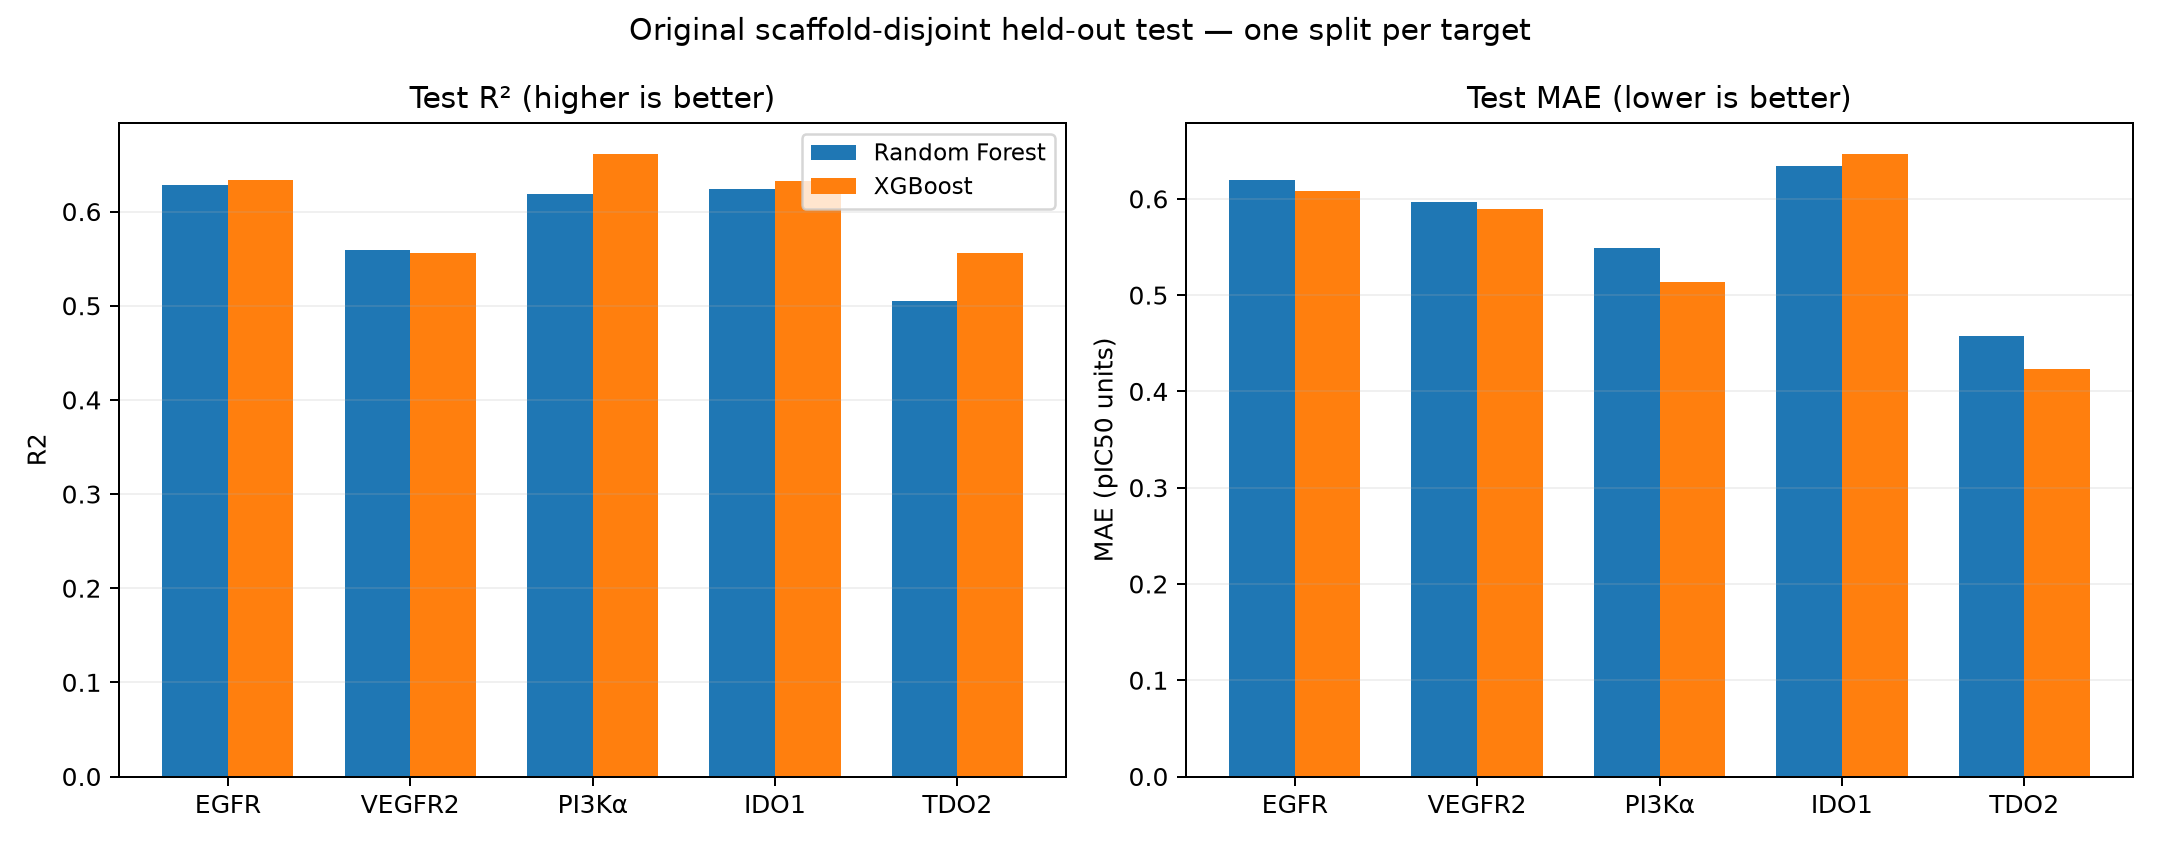

In [2]:
results = [r for r in rows(reports / 'all_targets_model_comparison.csv') if r['split'] == 'test']
for r in results:
    print(f"{r['target']:10} {r['model']:14} MAE={float(r['MAE']):.4f} RMSE={float(r['RMSE']):.4f} R2={float(r['R2']):.4f}")
display(Image(filename=str(reports / 'member5_final' / 'fig01_original_rf_vs_xgb.png')))


## Leakage and fingerprint collision sensitivity
Distinct molecules can share identical non-chiral folded fingerprints. Collision exclusion is a diagnostic, not an independent test set.


In [3]:
checks = rows(reports / 'final_validation' / 'leakage_and_dataset_audit.csv')
for r in checks:
    print(r['target'], 'scaffold overlap:', r['overlapping_scaffolds_train_test'],
          '| exact structures:', r['overlapping_canonical_smiles_train_test'],
          '| shared fingerprints:', r['overlapping_fingerprints_train_test'])


EGFR scaffold overlap: 0 | exact structures: 0 | shared fingerprints: 38
VEGFR2 scaffold overlap: 0 | exact structures: 0 | shared fingerprints: 16
PI3Kalpha scaffold overlap: 0 | exact structures: 0 | shared fingerprints: 22
IDO1 scaffold overlap: 0 | exact structures: 0 | shared fingerprints: 16
TDO2 scaffold overlap: 0 | exact structures: 0 | shared fingerprints: 1


## Alternative scaffold split robustness (Random Forest only)
Three new RF refits per target (seeds 13, 23, 37). XGBoost was **not** repeated.


EGFR R2 mean: 0.5538 SD: 0.0113
VEGFR2 R2 mean: 0.507 SD: 0.0391
PI3Kalpha R2 mean: 0.6069 SD: 0.0408
IDO1 R2 mean: 0.572 SD: 0.0253
TDO2 R2 mean: 0.3389 SD: 0.0546


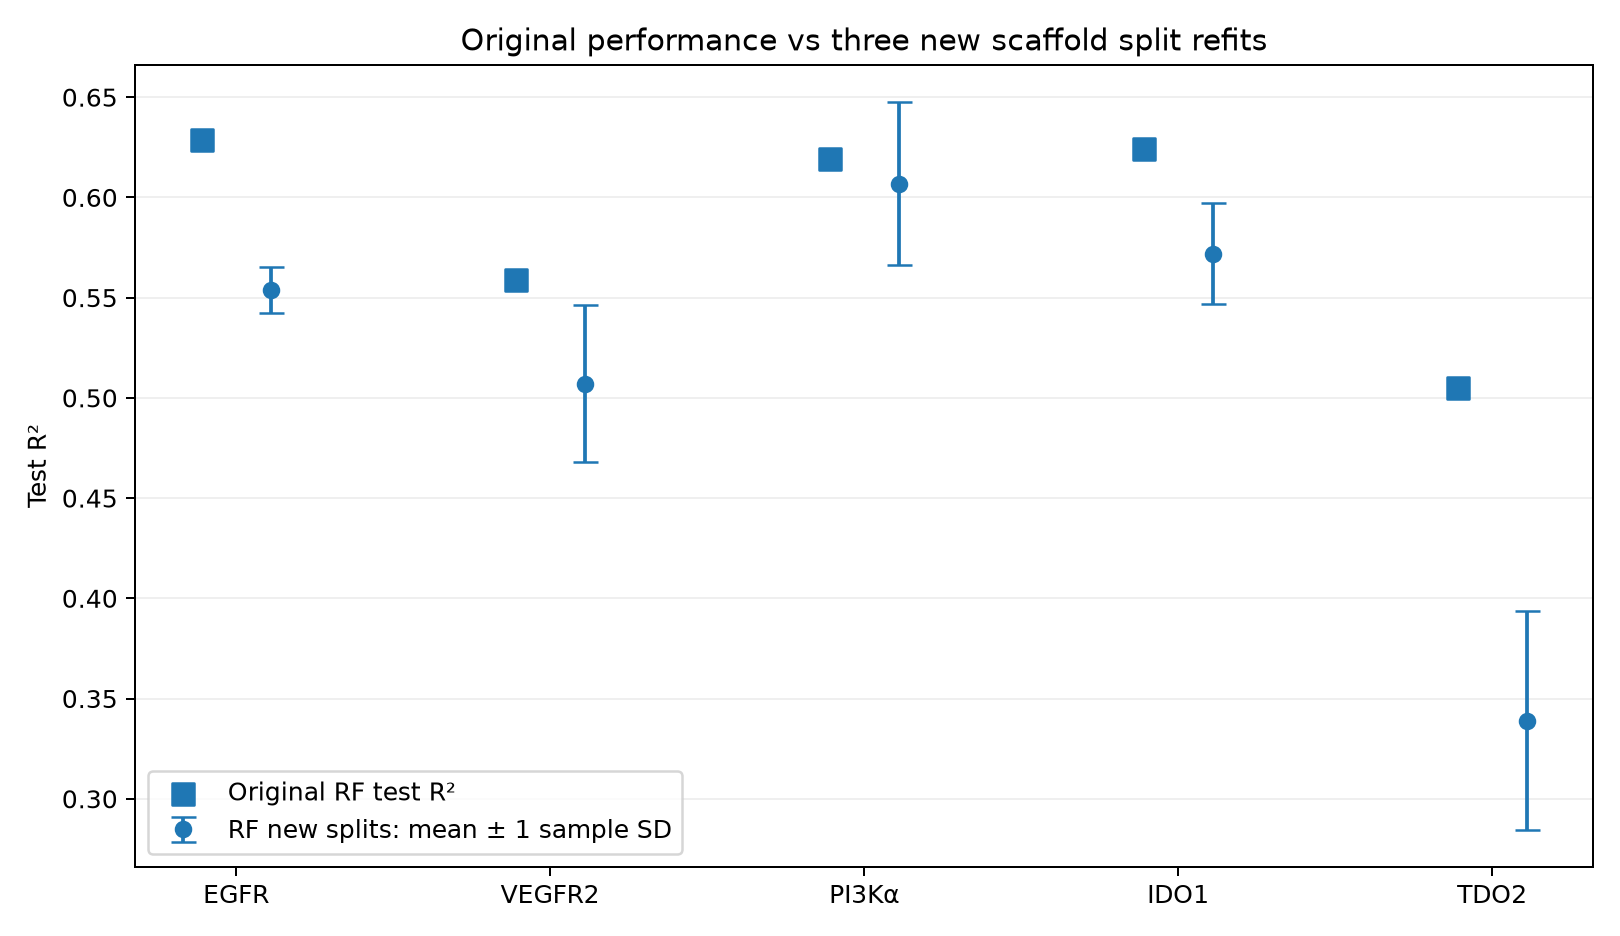

In [4]:
rob = rows(reports / 'final_validation' / 'repeated_scaffold_robustness' / 'rf_robustness_summary.csv')
for r in rob:
    print(r['target'], 'R2 mean:', round(float(r['R2_mean']),4), 'SD:',round(float(r['R2_std']),4))
display(Image(filename=str(reports / 'member5_final' / 'fig02_rf_scaffold_robustness.png')))


## Analog screening and final handover
Candidates are in-silico hypotheses; source datasets and assay comparability impose significant limitations.


Target–analog entries: 50
Unique Analog_IDs: 49
EGFR 10
IDO1 10
PI3Kalpha 10
TDO2 10
VEGFR2 10


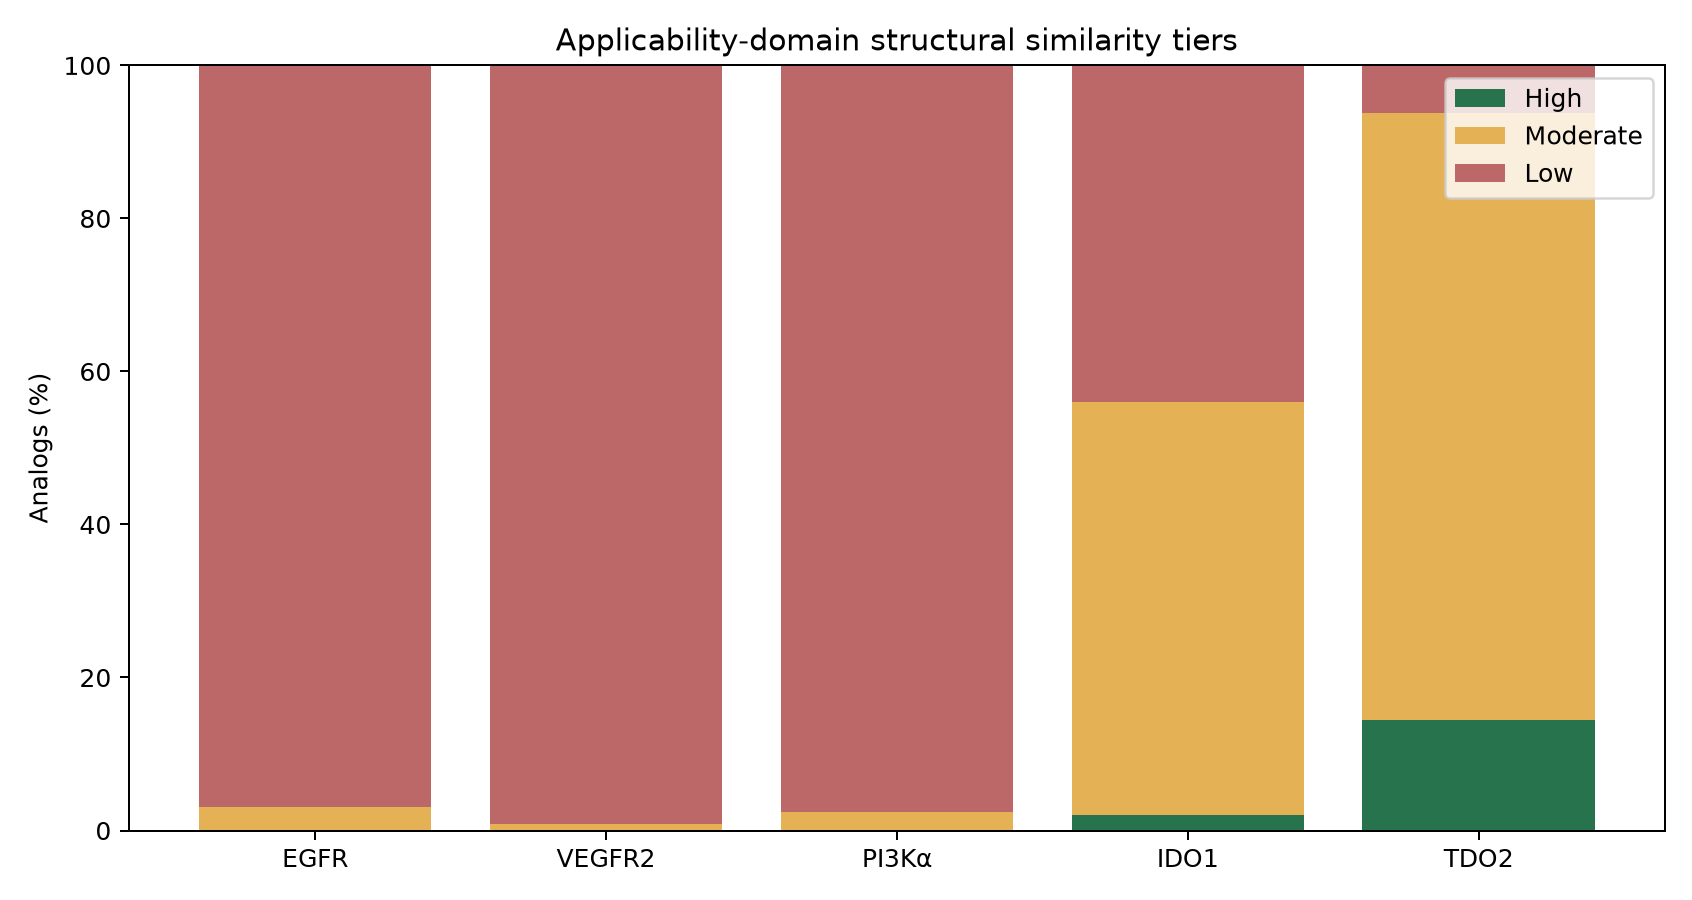

In [5]:
handover = rows(reports / 'diversity_shortlist' / 'master_docking_handover.csv')
print('Target–analog entries:',len(handover))
print('Unique Analog_IDs:',len({r['Analog_ID'] for r in handover}))
for t in sorted({r['Target'] for r in handover}):
    print(t, sum(r['Target']==t for r in handover))
if (reports/'member5_final'/'fig03_applicability_coverage.png').exists():
    display(Image(filename=str(reports/'member5_final'/'fig03_applicability_coverage.png')))


## Conclusions and limitations
- Regression on target-specific curated median pIC50, not binary class classification.
- Structural applicability is poor for EGFR, VEGFR2 and PI3Kα generated analog predictions.
- TDO2 has weaker performance under alternative scaffold splits; similarity support is not predictive confidence.
- Test results are from one original scaffold split; only Random Forest has a three-repeat robustness assessment.
- Parent compound predicted pIC50 and reference identities require independent checks; no experimentally validated anticancer hits are claimed.
- Team should confirm whether the original six-target scope was formally reduced to five.
